In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class CategorySemanticDecomposition(nn.Module):

    def __init__(self, input_dim=10, hidden_dim=64):

        super().__init__()

        self.input_projection = nn.Linear(
            input_dim, hidden_dim
        )

        self.normal_projection = nn.Linear(
            hidden_dim // 2, hidden_dim
        )

        self.abnormal_projection = nn.Linear(
            hidden_dim - hidden_dim // 2, hidden_dim
        )

    def forward(self, x):

        # Step 1: Map input features to latent space
        x = F.leaky_relu(
            self.input_projection(x)
        )

        # Step 2: Divide into two feature components
        x_normal_part, x_abnormal_part = torch.split(
            x,
            [32, 32],
            dim=1
        )

        # Step 3: Project into separate semantic subspaces
        x_normal = self.normal_projection(
            x_normal_part
        )

        x_abnormal = self.abnormal_projection(
            x_abnormal_part
        )

        return x_normal, x_abnormal

In [4]:
import torch
import dgl

# Load our saved processed graph
graphs, _ = dgl.load_graphs(
    "data/processed/tfinance_processed.bin"
)

g_processed = graphs[0]

# Restore features and labels
X = g_processed.ndata["feature"].float()
y = g_processed.ndata["class_label"].long()

print("Features:", X.shape)
print("Labels:", y.shape)

Features: torch.Size([39357, 10])
Labels: torch.Size([39357])


In [5]:
csd = CategorySemanticDecomposition(
    input_dim=10,
    hidden_dim=64
)

x_normal, x_abnormal = csd(X)

print("CSD TEST")
print("-" * 40)
print("Input:", X.shape)
print("Normal subspace:", x_normal.shape)
print("Abnormal subspace:", x_abnormal.shape)

CSD TEST
----------------------------------------
Input: torch.Size([39357, 10])
Normal subspace: torch.Size([39357, 64])
Abnormal subspace: torch.Size([39357, 64])


In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import dgl
from dgl.nn.functional import edge_softmax


class DenoisingAttention(nn.Module):

    def __init__(self, hidden_dim=64):

        super().__init__()

        # Attention transformation
        self.attention_transform = nn.Linear(
            hidden_dim, hidden_dim
        )

        # Convert attention representation into a scalar
        self.attention_score = nn.Linear(
            hidden_dim, 1, bias=False
        )

        # Update the centre node representation
        self.update_layer = nn.Linear(
            hidden_dim, hidden_dim
        )

    def forward(self, graph, x, x_normal, x_abnormal):

        src, dst = graph.edges()

        # Combine normal and abnormal components
        combined = x_normal + x_abnormal

        # Calculate attention scores for each neighbour
        hidden = torch.tanh(
            self.attention_transform(combined[src])
        )

        scores = self.attention_score(hidden)

        # Normalize attention over each centre node's neighbours
        alpha = edge_softmax(graph, scores)

        # Combine the two semantic components
        messages = (
            alpha * x_normal[src]
            + (1 - alpha) * x_abnormal[src]
        )

        # Aggregate messages at destination nodes
        aggregated = torch.zeros_like(x)

        aggregated.index_add_(
            0, dst, messages
        )

        # Degree normalization
        degree = graph.in_degrees().to(x.device).clamp(min=1)

        aggregated = aggregated / degree.sqrt().unsqueeze(1)

        # Update centre node representations
        output = self.update_layer(x + aggregated)

        return output, alpha

In [7]:
# Sample a maximum of 10 neighbours per node
sampled_graph = dgl.sampling.sample_neighbors(
    g_processed,
    torch.arange(g_processed.num_nodes()),
    fanout=10,
    edge_dir="in"
)

# Initialise denoising attention
attention = DenoisingAttention(hidden_dim=64)

# Run attention
attention_output, attention_weights = attention(
    sampled_graph,
    F.leaky_relu(csd.input_projection(X)),
    x_normal,
    x_abnormal
)

print("DENOISING ATTENTION TEST")
print("-" * 45)

print("Sampled edges:", sampled_graph.num_edges())
print("Attention output:", attention_output.shape)
print("Attention weights:", attention_weights.shape)

print("Minimum attention:", attention_weights.min().item())
print("Maximum attention:", attention_weights.max().item())

print("\nAttention component working!")

DENOISING ATTENTION TEST
---------------------------------------------
Sampled edges: 387301
Attention output: torch.Size([39357, 64])
Attention weights: torch.Size([387301, 1])
Minimum attention: 0.043807052075862885
Maximum attention: 1.0

Attention component working!


In [8]:
class CGNNClassifier(nn.Module):

    def __init__(self, hidden_dim=64, num_classes=2):

        super().__init__()

        self.classifier = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, embeddings):

        logits = self.classifier(embeddings)

        return logits

In [9]:
# Get initial embeddings
initial_embeddings = F.leaky_relu(
    csd.input_projection(X)
)

# Run denoising attention
attention_output, attention_weights = attention(
    sampled_graph,
    initial_embeddings,
    x_normal,
    x_abnormal
)

# Classification
classifier = CGNNClassifier(
    hidden_dim=64,
    num_classes=2
)

logits = classifier(attention_output)

probabilities = F.softmax(logits, dim=1)

predictions = probabilities.argmax(dim=1)

print("CLASSIFICATION TEST")
print("-" * 40)

print("Logits:", logits.shape)
print("Probabilities:", probabilities.shape)
print("Predictions:", predictions.shape)

print("First 5 predictions:", predictions[:5])
print("First 5 probabilities:\n", probabilities[:5])

CLASSIFICATION TEST
----------------------------------------
Logits: torch.Size([39357, 2])
Probabilities: torch.Size([39357, 2])
Predictions: torch.Size([39357])
First 5 predictions: tensor([0, 0, 0, 0, 0])
First 5 probabilities:
 tensor([[1.0000e+00, 2.3453e-36],
        [1.0000e+00, 0.0000e+00],
        [1.0000e+00, 6.4145e-33],
        [1.0000e+00, 0.0000e+00],
        [1.0000e+00, 8.9918e-26]], grad_fn=<SliceBackward0>)


In [10]:
# Get initial embeddings
initial_embeddings = F.leaky_relu(
    csd.input_projection(X)
)

# Run denoising attention
attention_output, attention_weights = attention(
    sampled_graph,
    initial_embeddings,
    x_normal,
    x_abnormal
)

# Classification
classifier = CGNNClassifier(
    hidden_dim=64,
    num_classes=2
)

logits = classifier(attention_output)

probabilities = F.softmax(logits, dim=1)

predictions = probabilities.argmax(dim=1)

print("CLASSIFICATION TEST")
print("-" * 40)

print("Logits:", logits.shape)
print("Probabilities:", probabilities.shape)
print("Predictions:", predictions.shape)

print("First 5 predictions:", predictions[:5])
print("First 5 probabilities:\n", probabilities[:5])

CLASSIFICATION TEST
----------------------------------------
Logits: torch.Size([39357, 2])
Probabilities: torch.Size([39357, 2])
Predictions: torch.Size([39357])
First 5 predictions: tensor([0, 0, 0, 0, 0])
First 5 probabilities:
 tensor([[1.0000e+00, 0.0000e+00],
        [1.0000e+00, 0.0000e+00],
        [1.0000e+00, 9.0216e-09],
        [1.0000e+00, 0.0000e+00],
        [1.0000e+00, 0.0000e+00]], grad_fn=<SliceBackward0>)


In [11]:
class CGNNClassifier(nn.Module):

    def __init__(self, hidden_dim=64, num_classes=2):

        super().__init__()

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, embeddings):

        return self.classifier(embeddings)


# Initialize the MLP
classifier = CGNNClassifier(
    hidden_dim=64,
    num_classes=2
)

# Generate predictions
logits = classifier(attention_output)

probabilities = F.softmax(logits, dim=1)

print("MLP CLASSIFIER TEST")
print("-" * 40)
print("Logits:", logits.shape)
print("Probabilities:", probabilities.shape)
print("Predictions:", logits.argmax(dim=1).shape)

MLP CLASSIFIER TEST
----------------------------------------
Logits: torch.Size([39357, 2])
Probabilities: torch.Size([39357, 2])
Predictions: torch.Size([39357])


In [12]:
# Original feature representations
normal_view = x_normal.detach().clone()
abnormal_view = x_abnormal.detach().clone()

print("SFP INPUT PREPARATION")
print("-" * 40)

print("Normal representation:", normal_view.shape)
print("Abnormal representation:", abnormal_view.shape)

print("Normal representation dtype:", normal_view.dtype)
print("Abnormal representation dtype:", abnormal_view.dtype)

print("Normal representation finite:",
      torch.isfinite(normal_view).all().item())

print("Abnormal representation finite:",
      torch.isfinite(abnormal_view).all().item())

SFP INPUT PREPARATION
----------------------------------------
Normal representation: torch.Size([39357, 64])
Abnormal representation: torch.Size([39357, 64])
Normal representation dtype: torch.float32
Abnormal representation dtype: torch.float32
Normal representation finite: True
Abnormal representation finite: True


In [13]:
def subspace_feature_perturbation(
    graph,
    x_normal,
    x_abnormal,
    alpha
):
    src, dst = graph.edges()

    # Sort edges by destination node.
    # This groups each centre node's neighbours together.
    order = torch.argsort(dst)

    src = src[order]
    dst = dst[order]
    alpha = alpha[order]

    normal = x_normal[src]
    abnormal = x_abnormal[src]

    # Find the boundaries of each centre node's neighbourhood
    _, counts = torch.unique_consecutive(
        dst,
        return_counts=True
    )

    normal_augmented = []
    abnormal_augmented = []

    start = 0

    for count in counts.tolist():

        end = start + count

        # Neighbour representations for this centre node
        normal_group = normal[start:end]
        abnormal_group = abnormal[start:end]

        # Randomly permute within each semantic subspace
        permutation = torch.randperm(
            count,
            device=normal.device
        )

        normal_fa = normal_group[permutation]
        abnormal_fa = abnormal_group[permutation]

        normal_augmented.append(
            normal_fa
        )

        abnormal_augmented.append(
            abnormal_fa
        )

        start = end

    normal_fa = torch.cat(normal_augmented, dim=0)
    abnormal_fa = torch.cat(abnormal_augmented, dim=0)

    # Equation (9): create two augmented message views
    x_tilde_normal = (
        alpha * normal_fa
        + (1 - alpha) * abnormal
    )

    x_tilde_abnormal = (
        alpha * normal
        + (1 - alpha) * abnormal_fa
    )

    return (
        x_tilde_normal,
        x_tilde_abnormal,
        dst
    )

In [14]:
torch.manual_seed(27)

x_tilde_normal, x_tilde_abnormal, dst_sorted = (
    subspace_feature_perturbation(
        sampled_graph,
        x_normal,
        x_abnormal,
        attention_weights
    )
)

print("SFP TEST")
print("-" * 45)

print("Original normal:", x_normal.shape)
print("Original abnormal:", x_abnormal.shape)

print("Augmented normal:", x_tilde_normal.shape)
print("Augmented abnormal:", x_tilde_abnormal.shape)

print("\nAll values finite:")
print("Normal:", torch.isfinite(x_tilde_normal).all().item())
print("Abnormal:", torch.isfinite(x_tilde_abnormal).all().item())

SFP TEST
---------------------------------------------
Original normal: torch.Size([39357, 64])
Original abnormal: torch.Size([39357, 64])
Augmented normal: torch.Size([387301, 64])
Augmented abnormal: torch.Size([387301, 64])

All values finite:
Normal: True
Abnormal: True


In [15]:
def subspace_feature_perturbation(
    graph,
    x_normal,
    x_abnormal,
    alpha
):
    src, dst = graph.edges()

    # Sort edges by destination node
    order = torch.argsort(dst)

    src = src[order]
    dst = dst[order]
    alpha = alpha[order]

    normal = x_normal[src]
    abnormal = x_abnormal[src]

    _, counts = torch.unique_consecutive(
        dst,
        return_counts=True
    )

    normal_fa = []
    abnormal_fa = []

    start = 0

    for count in counts.tolist():

        end = start + count

        normal_group = normal[start:end]
        abnormal_group = abnormal[start:end]

        # Independently permute each subspace
        perm_normal = torch.randperm(
            count, device=normal.device
        )

        perm_abnormal = torch.randperm(
            count, device=abnormal.device
        )

        normal_fa.append(normal_group[perm_normal])
        abnormal_fa.append(abnormal_group[perm_abnormal])

        start = end

    normal_fa = torch.cat(normal_fa, dim=0)
    abnormal_fa = torch.cat(abnormal_fa, dim=0)

    # Equation (9)
    x_tilde_normal = (
        alpha * normal_fa
        + (1 - alpha) * abnormal
    )

    x_tilde_abnormal = (
        alpha * normal
        + (1 - alpha) * abnormal_fa
    )

    return x_tilde_normal, x_tilde_abnormal, dst

In [16]:
torch.manual_seed(27)

x_tilde_normal, x_tilde_abnormal, dst_sorted = (
    subspace_feature_perturbation(
        sampled_graph,
        x_normal,
        x_abnormal,
        attention_weights
    )
)

print("Normal augmented:", x_tilde_normal.shape)
print("Abnormal augmented:", x_tilde_abnormal.shape)

Normal augmented: torch.Size([387301, 64])
Abnormal augmented: torch.Size([387301, 64])


In [17]:
def aggregate_augmented_messages(
    messages,
    dst,
    num_nodes,
    initial_embeddings,
    update_layer
):

    aggregated = torch.zeros_like(initial_embeddings)

    aggregated.index_add_(
        0, dst, messages
    )

    degree = torch.bincount(
        dst,
        minlength=num_nodes
    ).to(initial_embeddings.device)

    degree = degree.clamp(min=1)

    aggregated = aggregated / degree.sqrt().unsqueeze(1)

    # Equation (5): aggregate and update
    output = update_layer(
        initial_embeddings + aggregated
    )

    return output

In [18]:
initial_embeddings = F.leaky_relu(
    csd.input_projection(X)
)

normal_augmented_embeddings = aggregate_augmented_messages(
    x_tilde_normal,
    dst_sorted,
    g_processed.num_nodes(),
    initial_embeddings,
    attention.update_layer
)

abnormal_augmented_embeddings = aggregate_augmented_messages(
    x_tilde_abnormal,
    dst_sorted,
    g_processed.num_nodes(),
    initial_embeddings,
    attention.update_layer
)

print("Normal augmented embeddings:",
      normal_augmented_embeddings.shape)

print("Abnormal augmented embeddings:",
      abnormal_augmented_embeddings.shape)

Normal augmented embeddings: torch.Size([39357, 64])
Abnormal augmented embeddings: torch.Size([39357, 64])


In [19]:
# Original prediction
original_logits = classifier(attention_output)

# Two augmented predictions
normal_logits = classifier(normal_augmented_embeddings)
abnormal_logits = classifier(abnormal_augmented_embeddings)

# Convert logits into probabilities
y_original = F.softmax(original_logits, dim=1)
y_normal_aug = F.softmax(normal_logits, dim=1)
y_abnormal_aug = F.softmax(abnormal_logits, dim=1)

print("THREE-VIEW PREDICTION TEST")
print("-" * 45)

print("Original:", y_original.shape)
print("Normal augmented:", y_normal_aug.shape)
print("Abnormal augmented:", y_abnormal_aug.shape)

THREE-VIEW PREDICTION TEST
---------------------------------------------
Original: torch.Size([39357, 2])
Normal augmented: torch.Size([39357, 2])
Abnormal augmented: torch.Size([39357, 2])


In [20]:
def consistency_loss(
    original_predictions,
    normal_predictions,
    abnormal_predictions,
    unlabelled_indices
):

    # Select only unlabelled training nodes
    y = original_predictions[unlabelled_indices]
    y0 = normal_predictions[unlabelled_indices]
    y1 = abnormal_predictions[unlabelled_indices]

    # Cosine similarities
    similarity_0 = F.cosine_similarity(
        y, y0, dim=1
    )

    similarity_1 = F.cosine_similarity(
        y, y1, dim=1
    )

    # Numerical stability
    similarity_1 = similarity_1.clamp(min=1e-8)

    # Equation (10)
    loss = -(
        similarity_0 * torch.log(similarity_1)
    ).mean()

    return loss

In [22]:
import torch

splits = torch.load(
    "data/processed/experimental_splits.pt",
    map_location="cpu",
    weights_only=False
)

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]
test_idx = splits["test_idx"]

labelled_1 = splits["labelled_1"]
unlabelled_1 = splits["unlabelled_1"]

labelled_5 = splits["labelled_5"]
unlabelled_5 = splits["unlabelled_5"]

print("Experimental splits restored!")
print("1-label unlabelled nodes:", len(unlabelled_1))
print("5-label unlabelled nodes:", len(unlabelled_5))

Experimental splits restored!
1-label unlabelled nodes: 3913
5-label unlabelled nodes: 3826


In [23]:
L_CL = consistency_loss(
    y_original,
    y_normal_aug,
    y_abnormal_aug,
    unlabelled_1
)

print("CONSISTENCY LOSS TEST")
print("-" * 40)
print("Unlabelled nodes:", len(unlabelled_1))
print("Consistency loss:", L_CL.item())
print("Finite loss:", torch.isfinite(L_CL).item())

CONSISTENCY LOSS TEST
----------------------------------------
Unlabelled nodes: 3913
Consistency loss: 2.172242119513612e-08
Finite loss: True


In [24]:
# Select unlabelled training nodes
y = y_original[unlabelled_1]
y0 = y_normal_aug[unlabelled_1]
y1 = y_abnormal_aug[unlabelled_1]

# Calculate cosine similarities
sim_normal = F.cosine_similarity(y, y0, dim=1)
sim_abnormal = F.cosine_similarity(y, y1, dim=1)

print("CONSISTENCY DIAGNOSTICS")
print("-" * 45)

print("Original vs Normal augmented:")
print("Mean:", sim_normal.mean().item())
print("Minimum:", sim_normal.min().item())

print("\nOriginal vs Abnormal augmented:")
print("Mean:", sim_abnormal.mean().item())
print("Minimum:", sim_abnormal.min().item())

print("\nPrediction variation:")
print("Original std:", y.std().item())
print("Normal augmented std:", y0.std().item())
print("Abnormal augmented std:", y1.std().item())

CONSISTENCY DIAGNOSTICS
---------------------------------------------
Original vs Normal augmented:
Mean: 1.0
Minimum: 0.9999999403953552

Original vs Abnormal augmented:
Mean: 1.0
Minimum: 0.9999149441719055

Prediction variation:
Original std: 0.4999738335609436
Normal augmented std: 0.4999738037586212
Abnormal augmented std: 0.4999707043170929


In [25]:
print("PREDICTION COLLAPSE INVESTIGATION")
print("-" * 45)

print("Original probabilities:")
print("Minimum:", y_original.min().item())
print("Maximum:", y_original.max().item())
print("Mean:", y_original.mean().item())

print("\nFirst 10 predictions:")
print(y_original[:10])

print("\nPredicted class distribution:")
print(torch.bincount(
    y_original.argmax(dim=1),
    minlength=2
))

PREDICTION COLLAPSE INVESTIGATION
---------------------------------------------
Original probabilities:
Minimum: 0.0
Maximum: 1.0
Mean: 0.5

First 10 predictions:
tensor([[0.0000e+00, 1.0000e+00],
        [0.0000e+00, 1.0000e+00],
        [1.9828e-42, 1.0000e+00],
        [0.0000e+00, 1.0000e+00],
        [0.0000e+00, 1.0000e+00],
        [0.0000e+00, 1.0000e+00],
        [5.4519e-24, 1.0000e+00],
        [0.0000e+00, 1.0000e+00],
        [0.0000e+00, 1.0000e+00],
        [0.0000e+00, 1.0000e+00]], grad_fn=<SliceBackward0>)

Predicted class distribution:
tensor([   22, 39335])


In [26]:
print("LOGIT INSPECTION")
print("-" * 40)

print("Minimum logit:", original_logits.min().item())
print("Maximum logit:", original_logits.max().item())

print("Mean absolute logit:",
      original_logits.abs().mean().item())

print("Logit standard deviation:",
      original_logits.std().item())

LOGIT INSPECTION
----------------------------------------
Minimum logit: -7429.3125
Maximum logit: 5730.59375
Mean absolute logit: 209.53033447265625
Logit standard deviation: 348.4985656738281


In [27]:
def inspect_tensor(name, tensor):
    print(f"\n{name}")
    print("-" * 40)
    print("Shape:", tuple(tensor.shape))
    print("Minimum:", tensor.min().item())
    print("Maximum:", tensor.max().item())
    print("Mean:", tensor.mean().item())
    print("Std:", tensor.std().item())
    print("All finite:", torch.isfinite(tensor).all().item())


inspect_tensor("Original features", X)

initial_embeddings = F.leaky_relu(
    csd.input_projection(X)
)
inspect_tensor("Initial embeddings", initial_embeddings)

inspect_tensor("Normal subspace", x_normal)
inspect_tensor("Abnormal subspace", x_abnormal)

inspect_tensor("Attention output", attention_output)
inspect_tensor("Classifier logits", original_logits)


Original features
----------------------------------------
Shape: (39357, 10)
Minimum: 0.0
Maximum: 508174.0
Mean: 712.4375610351562
Std: 4971.234375
All finite: True

Initial embeddings
----------------------------------------
Shape: (39357, 64)
Minimum: -1733.7449951171875
Maximum: 152272.375
Mean: 387.077392578125
Std: 2023.068603515625
All finite: True

Normal subspace
----------------------------------------
Shape: (39357, 64)
Minimum: -62640.52734375
Maximum: 57550.265625
Mean: -12.252714157104492
Std: 740.2362060546875
All finite: True

Abnormal subspace
----------------------------------------
Shape: (39357, 64)
Minimum: -155036.390625
Maximum: 92106.828125
Mean: -120.56310272216797
Std: 1721.48876953125
All finite: True

Attention output
----------------------------------------
Shape: (39357, 64)
Minimum: -76026.78125
Maximum: 85923.9296875
Mean: -13.80921745300293
Std: 2138.5234375
All finite: True

Classifier logits
----------------------------------------
Shape: (39357, 2)

In [28]:
X_log = torch.log1p(X)

inspect_tensor("Log-transformed features", X_log)


Log-transformed features
----------------------------------------
Shape: (39357, 10)
Minimum: 0.0
Maximum: 13.138581275939941
Mean: 3.481292486190796
Std: 2.5503761768341064
All finite: True


In [29]:
# Step 1: Apply log transformation
X_log = torch.log1p(X)

# Step 2: Calculate statistics using training nodes only
X_train = X_log[train_idx]

feature_mean = X_train.mean(dim=0)
feature_std = X_train.std(dim=0)

# Avoid division by zero
feature_std = torch.where(
    feature_std == 0,
    torch.ones_like(feature_std),
    feature_std
)

# Step 3: Standardize all nodes using training statistics
X_standardized = (X_log - feature_mean) / feature_std

# Step 4: Inspect the result
inspect_tensor("Standardized features", X_standardized)


Standardized features
----------------------------------------
Shape: (39357, 10)
Minimum: -3.39334774017334
Maximum: 5.196847438812256
Mean: -0.004277778789401054
Std: 1.000880479812622
All finite: True


In [30]:
print("FEATURE PREPROCESSING COMPARISON")
print("=" * 50)

print("Original:")
print("Mean:", X.mean().item())
print("Std:", X.std().item())

print("\nLog transformed:")
print("Mean:", X_log.mean().item())
print("Std:", X_log.std().item())

print("\nLog + Standardization:")
print("Mean:", X_standardized.mean().item())
print("Std:", X_standardized.std().item())

FEATURE PREPROCESSING COMPARISON
Original:
Mean: 712.4375610351562
Std: 4971.234375

Log transformed:
Mean: 3.481292486190796
Std: 2.5503761768341064

Log + Standardization:
Mean: -0.004277778789401054
Std: 1.000880479812622


In [31]:
# 1. Generate new initial embeddings
initial_embeddings_std = F.leaky_relu(
    csd.input_projection(X_standardized)
)

# 2. Generate normal and abnormal subspaces
x_normal_std, x_abnormal_std = csd(X_standardized)

# 3. Run denoising attention
attention_output_std, alpha_std = attention(
    sampled_graph,
    initial_embeddings_std,
    x_normal_std,
    x_abnormal_std
)

# 4. Generate classifier logits
original_logits_std = classifier(attention_output_std)

# 5. Convert logits to probabilities
y_original_std = F.softmax(original_logits_std, dim=1)

In [32]:
inspect_tensor("Standardized initial embeddings", initial_embeddings_std)
inspect_tensor("Standardized normal subspace", x_normal_std)
inspect_tensor("Standardized abnormal subspace", x_abnormal_std)
inspect_tensor("Standardized attention output", attention_output_std)
inspect_tensor("Standardized classifier logits", original_logits_std)

print("\nPREDICTION DISTRIBUTION")
print(torch.bincount(y_original_std.argmax(dim=1), minlength=2))


Standardized initial embeddings
----------------------------------------
Shape: (39357, 64)
Minimum: -0.04397990182042122
Maximum: 4.203980445861816
Mean: 0.23154398798942566
Std: 0.3752433657646179
All finite: True

Standardized normal subspace
----------------------------------------
Shape: (39357, 64)
Minimum: -1.821480393409729
Maximum: 1.849921464920044
Mean: 0.014149384573101997
Std: 0.24058668315410614
All finite: True

Standardized abnormal subspace
----------------------------------------
Shape: (39357, 64)
Minimum: -2.8586854934692383
Maximum: 2.524848222732544
Mean: 0.016656985506415367
Std: 0.31567052006721497
All finite: True

Standardized attention output
----------------------------------------
Shape: (39357, 64)
Minimum: -2.75152587890625
Maximum: 2.589923143386841
Mean: 0.05528709292411804
Std: 0.4866343140602112
All finite: True

Standardized classifier logits
----------------------------------------
Shape: (39357, 2)
Minimum: -0.39689305424690247
Maximum: 0.26011976

In [33]:
print("PREDICTION CONFIDENCE")
print("=" * 40)

print("Minimum probability:", y_original_std.min().item())
print("Maximum probability:", y_original_std.max().item())

print("\nFirst 10 predictions:")
print(y_original_std[:10])

print("\nAverage probability per class:")
print(y_original_std.mean(dim=0))

PREDICTION CONFIDENCE
Minimum probability: 0.35174891352653503
Maximum probability: 0.6482511162757874

First 10 predictions:
tensor([[0.5120, 0.4880],
        [0.4358, 0.5642],
        [0.4940, 0.5060],
        [0.4850, 0.5150],
        [0.5181, 0.4819],
        [0.4659, 0.5341],
        [0.4744, 0.5256],
        [0.4786, 0.5214],
        [0.4906, 0.5094],
        [0.5010, 0.4990]], grad_fn=<SliceBackward0>)

Average probability per class:
tensor([0.4791, 0.5209], grad_fn=<MeanBackward1>)


In [35]:
print("INDEXING DIAGNOSTIC")
print("=" * 40)

print("y shape:", y.shape)
print("labelled_1 shape:", labelled_1.shape)
print("labelled_5 shape:", labelled_5.shape)

print("Maximum labelled_1 index:", labelled_1.max().item())
print("Maximum labelled_5 index:", labelled_5.max().item())

print("Original graph nodes:", g_processed.num_nodes())

INDEXING DIAGNOSTIC
y shape: torch.Size([3913, 2])
labelled_1 shape: torch.Size([22])
labelled_5 shape: torch.Size([109])
Maximum labelled_1 index: 37578
Maximum labelled_5 index: 38982
Original graph nodes: 39357


In [36]:
# Restore labels for every node in the original graph
y_global = g_processed.ndata["class_label"].long()

print("Global labels shape:", y_global.shape)

print("\n1-label experiment:")
print("Labelled nodes:", len(labelled_1))
print("Classes:", torch.bincount(y_global[labelled_1]))

print("\n5-label experiment:")
print("Labelled nodes:", len(labelled_5))
print("Classes:", torch.bincount(y_global[labelled_5]))

Global labels shape: torch.Size([39357])

1-label experiment:
Labelled nodes: 22
Classes: tensor([21,  1])

5-label experiment:
Labelled nodes: 109
Classes: tensor([104,   5])


In [39]:
# Convert global labels to class indices
y_global = g_processed.ndata["class_label"].long()

# Extract labelled node IDs
labelled_1 = labelled_1.long()
labelled_5 = labelled_5.long()

# Extract labelled classes
labels_1 = y_global[labelled_1]
labels_5 = y_global[labelled_5]

print("1-label class counts:")
print(torch.bincount(labels_1, minlength=2))

print("\n5-label class counts:")
print(torch.bincount(labels_5, minlength=2))

# Verify the semantic representations
print("\nRepresentation shapes:")
print("Normal:", x_normal_std.shape)
print("Abnormal:", x_abnormal_std.shape)

1-label class counts:
tensor([21,  1])

5-label class counts:
tensor([104,   5])

Representation shapes:
Normal: torch.Size([39357, 64])
Abnormal: torch.Size([39357, 64])


In [40]:
import torch
import torch.nn.functional as F

def csd_contrastive_loss(
    x_normal,
    x_abnormal,
    labelled_indices,
    global_labels,
    tau=0.8
):
    # 1. Get labels for the selected nodes
    labelled_indices = labelled_indices.long()
    labels = global_labels[labelled_indices]

    # 2. Select the category-specific representation
    normal_mask = labels == 0
    abnormal_mask = labels == 1

    embeddings = torch.zeros(
        len(labelled_indices),
        x_normal.shape[1],
        device=x_normal.device
    )

    embeddings[normal_mask] = x_normal[labelled_indices[normal_mask]]
    embeddings[abnormal_mask] = x_abnormal[labelled_indices[abnormal_mask]]

    # 3. Normalize embeddings for cosine similarity
    embeddings = F.normalize(embeddings, p=2, dim=1)

    # 4. Calculate pairwise cosine similarities
    similarity = torch.mm(embeddings, embeddings.T)

    # 5. Construct positive and negative pair masks
    same_class = labels.unsqueeze(0) == labels.unsqueeze(1)

    # Exclude each node from being paired with itself
    identity = torch.eye(
        len(labelled_indices),
        dtype=torch.bool,
        device=embeddings.device
    )

    positive_mask = same_class & ~identity
    negative_mask = ~same_class

    # 6. Calculate the contrastive loss
    anchor_losses = []

    for i in range(len(labelled_indices)):

        positive_similarities = similarity[i][positive_mask[i]]
        negative_similarities = similarity[i][negative_mask[i]]

        # Skip anchors without both positive and negative pairs
        if len(positive_similarities) == 0:
            continue

        if len(negative_similarities) == 0:
            continue

        positive_log_sum = torch.logsumexp(
            positive_similarities / tau,
            dim=0
        )

        negative_log_sum = torch.logsumexp(
            negative_similarities / tau,
            dim=0
        )

        loss_i = -(
            positive_log_sum - negative_log_sum
        ) / len(positive_similarities)

        anchor_losses.append(loss_i)

    # 7. Average over eligible anchors
    if len(anchor_losses) == 0:
        return embeddings.sum() * 0.0, 0

    loss = torch.stack(anchor_losses).mean()

    return loss, len(anchor_losses)

In [41]:
loss_csd_1, anchors_1 = csd_contrastive_loss(
    x_normal_std,
    x_abnormal_std,
    labelled_1,
    y_global,
    tau=0.8
)

print("1-LABEL CSD CONTRASTIVE LOSS")
print("=" * 40)
print("Loss:", loss_csd_1.item())
print("Eligible anchors:", anchors_1)
print("Finite:", torch.isfinite(loss_csd_1).item())

1-LABEL CSD CONTRASTIVE LOSS
Loss: -0.17229130864143372
Eligible anchors: 21
Finite: True


In [42]:
loss_csd_5, anchors_5 = csd_contrastive_loss(
    x_normal_std,
    x_abnormal_std,
    labelled_5,
    y_global,
    tau=0.8
)

print("5-LABEL CSD CONTRASTIVE LOSS")
print("=" * 40)
print("Loss:", loss_csd_5.item())
print("Eligible anchors:", anchors_5)
print("Finite:", torch.isfinite(loss_csd_5).item())

5-LABEL CSD CONTRASTIVE LOSS
Loss: -0.006542732939124107
Eligible anchors: 109
Finite: True


In [43]:
def inspect_csd_pairs(
    x_normal,
    x_abnormal,
    labelled_indices,
    global_labels,
    tau=0.8
):
    labels = global_labels[labelled_indices]

    normal_mask = labels == 0
    abnormal_mask = labels == 1

    embeddings = torch.zeros(
        len(labelled_indices),
        x_normal.shape[1],
        device=x_normal.device
    )

    embeddings[normal_mask] = x_normal[labelled_indices[normal_mask]]
    embeddings[abnormal_mask] = x_abnormal[labelled_indices[abnormal_mask]]

    embeddings = F.normalize(embeddings, dim=1)
    similarity = embeddings @ embeddings.T

    same_class = labels[:, None] == labels[None, :]
    identity = torch.eye(
        len(labels), dtype=torch.bool, device=labels.device
    )

    positive_mask = same_class & ~identity
    negative_mask = ~same_class

    print("Average positive cosine similarity:",
          similarity[positive_mask].mean().item())

    print("Average negative cosine similarity:",
          similarity[negative_mask].mean().item())

    print("Average positive pairs per anchor:",
          positive_mask.sum(dim=1).float().mean().item())

    print("Average negative pairs per anchor:",
          negative_mask.sum(dim=1).float().mean().item())


print("1-LABEL EXPERIMENT")
inspect_csd_pairs(
    x_normal_std, x_abnormal_std,
    labelled_1, y_global
)

print("\n5-LABEL EXPERIMENT")
inspect_csd_pairs(
    x_normal_std, x_abnormal_std,
    labelled_5, y_global
)

1-LABEL EXPERIMENT
Average positive cosine similarity: 0.4876573979854584
Average negative cosine similarity: 0.15267202258110046
Average positive pairs per anchor: 19.090909957885742
Average negative pairs per anchor: 1.9090908765792847

5-LABEL EXPERIMENT
Average positive cosine similarity: 0.4972206950187683
Average negative cosine similarity: 0.12046592682600021
Average positive pairs per anchor: 98.4587173461914
Average negative pairs per anchor: 9.541284561157227


In [44]:
# Original graph
graph = g_processed

# Standardized node features
features = X_standardized

# Global node labels
labels = g_processed.ndata["class_label"].long()

# Experimental indices
splits = torch.load(
    "data/processed/experimental_splits.pt",
    map_location="cpu",
    weights_only=False
)

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]
test_idx = splits["test_idx"]

labelled_1 = splits["labelled_1"]
unlabelled_1 = splits["unlabelled_1"]

labelled_5 = splits["labelled_5"]
unlabelled_5 = splits["unlabelled_5"]

print("Graph nodes:", graph.num_nodes())
print("Feature shape:", features.shape)
print("Label shape:", labels.shape)
print("Training nodes:", len(train_idx))

Graph nodes: 39357
Feature shape: torch.Size([39357, 10])
Label shape: torch.Size([39357])
Training nodes: 3935


In [45]:
modules = {
    "CSD": csd,
    "Attention": attention,
    "Classifier": classifier
}

for name, module in modules.items():
    trainable = sum(
        p.numel()
        for p in module.parameters()
        if p.requires_grad
    )

    print(f"{name}: {trainable:,} trainable parameters")

CSD: 4,928 trainable parameters
Attention: 8,384 trainable parameters
Classifier: 4,290 trainable parameters


In [46]:
class CGNNModel(nn.Module):

    def __init__(self, input_dim=10, hidden_dim=64, num_classes=2):
        super().__init__()

        self.csd = CategorySemanticDecomposition(
            input_dim=input_dim,
            hidden_dim=hidden_dim
        )

        self.attention = DenoisingAttention(
            hidden_dim=hidden_dim
        )

        self.classifier = CGNNClassifier(
            hidden_dim=hidden_dim,
            num_classes=num_classes
        )

    def forward(self, graph, features):

        # Step 1: Category Semantic Decomposition
        x = F.leaky_relu(
            self.csd.input_projection(features)
        )

        x_normal, x_abnormal = self.csd(features)

        # Step 2: Denoising Attention
        embeddings, attention_weights = self.attention(
            graph,
            x,
            x_normal,
            x_abnormal
        )

        # Step 3: Classification
        logits = self.classifier(embeddings)

        return logits, embeddings, attention_weights

In [47]:
model = CGNNModel(
    input_dim=10,
    hidden_dim=64,
    num_classes=2
)

print(model)

CGNNModel(
  (csd): CategorySemanticDecomposition(
    (input_projection): Linear(in_features=10, out_features=64, bias=True)
    (normal_projection): Linear(in_features=32, out_features=64, bias=True)
    (abnormal_projection): Linear(in_features=32, out_features=64, bias=True)
  )
  (attention): DenoisingAttention(
    (attention_transform): Linear(in_features=64, out_features=64, bias=True)
    (attention_score): Linear(in_features=64, out_features=1, bias=False)
    (update_layer): Linear(in_features=64, out_features=64, bias=True)
  )
  (classifier): CGNNClassifier(
    (classifier): Sequential(
      (0): Linear(in_features=64, out_features=64, bias=True)
      (1): LeakyReLU(negative_slope=0.01)
      (2): Linear(in_features=64, out_features=2, bias=True)
    )
  )
)


In [48]:
total_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total trainable parameters: {total_parameters:,}")

Total trainable parameters: 17,602


In [50]:
model.eval()

with torch.no_grad():
    logits, embeddings, attention_weights = model(
        g_processed,
        X_standardized
    )

print("LOGITS SHAPE:", logits.shape)
print("EMBEDDINGS SHAPE:", embeddings.shape)
print("ATTENTION WEIGHTS SHAPE:", attention_weights.shape)

print("\nAll logits finite:", torch.isfinite(logits).all().item())
print("All embeddings finite:", torch.isfinite(embeddings).all().item())
print("All attention weights finite:", torch.isfinite(attention_weights).all().item())

RuntimeError: [enforce fail at alloc_cpu.cpp:114] data. DefaultCPUAllocator: not enough memory: you tried to allocate 10865942016 bytes.

In [51]:
model.eval()

with torch.no_grad():

    logits, embeddings, attention_weights = model(
        sampled_graph,
        X_standardized
    )

print("LOGITS SHAPE:", logits.shape)
print("EMBEDDINGS SHAPE:", embeddings.shape)
print("ATTENTION WEIGHTS SHAPE:", attention_weights.shape)

print("\nAll logits finite:", torch.isfinite(logits).all().item())
print("All embeddings finite:", torch.isfinite(embeddings).all().item())
print("All attention weights finite:", torch.isfinite(attention_weights).all().item())

LOGITS SHAPE: torch.Size([39357, 2])
EMBEDDINGS SHAPE: torch.Size([39357, 64])
ATTENTION WEIGHTS SHAPE: torch.Size([387301, 1])

All logits finite: True
All embeddings finite: True
All attention weights finite: True


In [52]:
# Load the saved experimental splits
splits = torch.load(
    "data/processed/experimental_splits.pt",
    map_location="cpu",
    weights_only=False
)

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]
test_idx = splits["test_idx"]

labelled_1 = splits["labelled_1"]
unlabelled_1 = splits["unlabelled_1"]

labelled_5 = splits["labelled_5"]
unlabelled_5 = splits["unlabelled_5"]

# Global labels for all nodes
labels = g_processed.ndata["class_label"].long()

print("TRAINING DATA")
print("Training nodes:", len(train_idx))
print("Validation nodes:", len(val_idx))
print("Test nodes:", len(test_idx))

print("\n1-LABEL SETTING")
print("Labelled nodes:", len(labelled_1))
print("Unlabelled nodes:", len(unlabelled_1))
print("Labelled class counts:", torch.bincount(labels[labelled_1]))

print("\n5-LABEL SETTING")
print("Labelled nodes:", len(labelled_5))
print("Unlabelled nodes:", len(unlabelled_5))
print("Labelled class counts:", torch.bincount(labels[labelled_5]))

TRAINING DATA
Training nodes: 3935
Validation nodes: 11807
Test nodes: 23615

1-LABEL SETTING
Labelled nodes: 22
Unlabelled nodes: 3913
Labelled class counts: tensor([21,  1])

5-LABEL SETTING
Labelled nodes: 109
Unlabelled nodes: 3826
Labelled class counts: tensor([104,   5])


In [53]:
print("Graph nodes:", sampled_graph.num_nodes())
print("Feature rows:", X_standardized.shape[0])
print("Label count:", labels.shape[0])

assert sampled_graph.num_nodes() == X_standardized.shape[0]
assert X_standardized.shape[0] == labels.shape[0]

print("\nGraph, features and labels are aligned!")

Graph nodes: 39357
Feature rows: 39357
Label count: 39357

Graph, features and labels are aligned!


In [54]:
# Get labels of the 1-label training subset
labelled_targets = labels[labelled_1]

# Count samples in each class
class_counts = torch.bincount(
    labelled_targets,
    minlength=2
).float()

# Calculate inverse-frequency class weights
class_weights = class_counts.sum() / (2 * class_counts)

print("Class counts:", class_counts)
print("Class weights:", class_weights)

Class counts: tensor([21.,  1.])
Class weights: tensor([ 0.5238, 11.0000])


In [55]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

print(criterion)

CrossEntropyLoss()


In [56]:
model.eval()

with torch.no_grad():
    logits, embeddings, attention_weights = model(
        sampled_graph,
        X_standardized
    )

    labelled_logits = logits[labelled_1]
    labelled_targets = labels[labelled_1]

    initial_loss = criterion(
        labelled_logits,
        labelled_targets
    )

print("Initial supervised loss:", initial_loss.item())
print("Loss is finite:", torch.isfinite(initial_loss).item())

Initial supervised loss: 0.6796640753746033
Loss is finite: True


In [57]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=1e-4
)

print("Optimizer:", optimizer)

Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0.0001
)


In [58]:
model.train()

# Clear previous gradients
optimizer.zero_grad()

# Forward pass
logits, embeddings, attention_weights = model(
    sampled_graph,
    X_standardized
)

# Select only labelled training nodes
labelled_logits = logits[labelled_1]
labelled_targets = labels[labelled_1]

# Calculate supervised loss
loss = criterion(labelled_logits, labelled_targets)

# Backpropagation
loss.backward()

# Update model parameters
optimizer.step()

print("Training loss:", loss.item())
print("One training step completed!")

Training loss: 0.6796640753746033
One training step completed!


In [59]:
for name, parameter in model.named_parameters():
    if parameter.grad is not None:
        print(
            f"{name}: gradient calculated = "
            f"{torch.isfinite(parameter.grad).all().item()}"
        )
    else:
        print(f"{name}: NO GRADIENT")

csd.input_projection.weight: gradient calculated = True
csd.input_projection.bias: gradient calculated = True
csd.normal_projection.weight: gradient calculated = True
csd.normal_projection.bias: gradient calculated = True
csd.abnormal_projection.weight: gradient calculated = True
csd.abnormal_projection.bias: gradient calculated = True
attention.attention_transform.weight: gradient calculated = True
attention.attention_transform.bias: gradient calculated = True
attention.attention_score.weight: gradient calculated = True
attention.update_layer.weight: gradient calculated = True
attention.update_layer.bias: gradient calculated = True
classifier.classifier.0.weight: gradient calculated = True
classifier.classifier.0.bias: gradient calculated = True
classifier.classifier.2.weight: gradient calculated = True
classifier.classifier.2.bias: gradient calculated = True


In [60]:
model.eval()

with torch.no_grad():
    updated_logits, _, _ = model(
        sampled_graph,
        X_standardized
    )

    updated_loss = criterion(
        updated_logits[labelled_1],
        labels[labelled_1]
    )

print("Loss before update: 0.679664")
print("Loss after update:", updated_loss.item())

Loss before update: 0.679664
Loss after update: 0.3818925619125366


In [61]:
import random
import numpy as np
import torch

def set_seed(seed=27):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(27)

# Reinitialize the model
model = CGNNModel(
    input_dim=10,
    hidden_dim=64,
    num_classes=2
)

# Initialize a fresh optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=1e-4
)

print("Fresh model initialized.")
print("Random seed: 27")
print("Learning rate: 0.01")
print("Weight decay: 0.0001")

Fresh model initialized.
Random seed: 27
Learning rate: 0.01
Weight decay: 0.0001


In [62]:
model.eval()

with torch.no_grad():
    x_normal, x_abnormal = model.csd(X_standardized)

print("Normal representations:", x_normal.shape)
print("Abnormal representations:", x_abnormal.shape)

print("Normal representations finite:",
      torch.isfinite(x_normal).all().item())

print("Abnormal representations finite:",
      torch.isfinite(x_abnormal).all().item())

Normal representations: torch.Size([39357, 64])
Abnormal representations: torch.Size([39357, 64])
Normal representations finite: True
Abnormal representations finite: True


In [63]:
# One labelled fraud node
loss_csd_1, anchors_1 = csd_contrastive_loss(
    x_normal,
    x_abnormal,
    labelled_1,
    labels,
    tau=0.8
)

# Five labelled fraud nodes
loss_csd_5, anchors_5 = csd_contrastive_loss(
    x_normal,
    x_abnormal,
    labelled_5,
    labels,
    tau=0.8
)

print("CSD CONTRASTIVE LOSS")

print("\n1-label experiment:")
print("Loss:", loss_csd_1.item())
print("Eligible anchors:", anchors_1)

print("\n5-label experiment:")
print("Loss:", loss_csd_5.item())
print("Eligible anchors:", anchors_5)

print("\nLoss finite:",
      torch.isfinite(loss_csd_1).item()
      and torch.isfinite(loss_csd_5).item())

CSD CONTRASTIVE LOSS

1-label experiment:
Loss: -0.1951977014541626
Eligible anchors: 21

5-label experiment:
Loss: -0.012740697711706161
Eligible anchors: 109

Loss finite: True


In [64]:
# One labelled fraud node
loss_csd_1, anchors_1 = csd_contrastive_loss(
    x_normal,
    x_abnormal,
    labelled_1,
    labels,
    tau=0.8
)

# Five labelled fraud nodes
loss_csd_5, anchors_5 = csd_contrastive_loss(
    x_normal,
    x_abnormal,
    labelled_5,
    labels,
    tau=0.8
)

print("CSD CONTRASTIVE LOSS")

print("\n1-label experiment:")
print("Loss:", loss_csd_1.item())
print("Eligible anchors:", anchors_1)

print("\n5-label experiment:")
print("Loss:", loss_csd_5.item())
print("Eligible anchors:", anchors_5)

print("\nLoss finite:",
      torch.isfinite(loss_csd_1).item()
      and torch.isfinite(loss_csd_5).item())

CSD CONTRASTIVE LOSS

1-label experiment:
Loss: -0.1951977014541626
Eligible anchors: 21

5-label experiment:
Loss: -0.012740697711706161
Eligible anchors: 109

Loss finite: True


In [65]:
def csd_contrastive_loss_v2(
    x_normal,
    x_abnormal,
    labelled_indices,
    global_labels,
    tau=0.8
):
    labelled_indices = labelled_indices.long()
    device = x_normal.device

    labels_batch = global_labels[labelled_indices]

    # Select the category-preserving semantic subspace
    embeddings = torch.where(
        (labels_batch == 0).unsqueeze(1),
        x_normal[labelled_indices],
        x_abnormal[labelled_indices]
    )

    embeddings = F.normalize(embeddings, p=2, dim=1)

    # Cosine similarity between labelled samples
    similarity = embeddings @ embeddings.T

    same_class = (
        labels_batch.unsqueeze(0) ==
        labels_batch.unsqueeze(1)
    )

    identity = torch.eye(
        len(labelled_indices),
        dtype=torch.bool,
        device=device
    )

    positive_mask = same_class & ~identity
    negative_mask = ~same_class

    anchor_losses = []

    for i in range(len(labelled_indices)):

        positive_sim = similarity[i][positive_mask[i]]
        negative_sim = similarity[i][negative_mask[i]]

        if positive_sim.numel() == 0 or negative_sim.numel() == 0:
            continue

        positive_log_sum = torch.logsumexp(
            positive_sim / tau, dim=0
        )

        negative_log_sum = torch.logsumexp(
            negative_sim / tau, dim=0
        )

        loss_i = -(positive_log_sum - negative_log_sum)

        anchor_losses.append(loss_i)

    if not anchor_losses:
        return embeddings.sum() * 0.0, 0

    loss = torch.stack(anchor_losses).mean()

    return loss, len(anchor_losses)

In [66]:
loss_csd_1_v2, anchors_1_v2 = csd_contrastive_loss_v2(
    x_normal,
    x_abnormal,
    labelled_1,
    labels,
    tau=0.8
)

loss_csd_5_v2, anchors_5_v2 = csd_contrastive_loss_v2(
    x_normal,
    x_abnormal,
    labelled_5,
    labels,
    tau=0.8
)

print("CORRECTED CSD LOSS")

print("1-label loss:", loss_csd_1_v2.item())
print("1-label anchors:", anchors_1_v2)

print("5-label loss:", loss_csd_5_v2.item())
print("5-label anchors:", anchors_5_v2)

CORRECTED CSD LOSS
1-label loss: -3.903954267501831
1-label anchors: 21
5-label loss: -3.616084098815918
5-label anchors: 109


In [67]:
model.train()

# Clear previous gradients
model.zero_grad()

# Generate fresh representations with gradients enabled
x_normal, x_abnormal = model.csd(X_standardized)

# Calculate CSD contrastive loss
loss_csd, anchors = csd_contrastive_loss_v2(
    x_normal,
    x_abnormal,
    labelled_1,
    labels,
    tau=0.8
)

# Backpropagate
loss_csd.backward()

print("CSD loss:", loss_csd.item())
print("Eligible anchors:", anchors)

print("\nCSD GRADIENT CHECK")

for name, parameter in model.csd.named_parameters():
    print(
        name,
        "Gradient exists:", parameter.grad is not None,
        "Finite:", (
            torch.isfinite(parameter.grad).all().item()
            if parameter.grad is not None else False
        )
    )

CSD loss: -3.903954267501831
Eligible anchors: 21

CSD GRADIENT CHECK
input_projection.weight Gradient exists: True Finite: True
input_projection.bias Gradient exists: True Finite: True
normal_projection.weight Gradient exists: True Finite: True
normal_projection.bias Gradient exists: True Finite: True
abnormal_projection.weight Gradient exists: True Finite: True
abnormal_projection.bias Gradient exists: True Finite: True


In [68]:
model.eval()

with torch.no_grad():

    x_normal, x_abnormal = model.csd(X_standardized)

    # Generate attention weights
    x = F.leaky_relu(
        model.csd.input_projection(X_standardized)
    )

    _, attention_weights = model.attention(
        sampled_graph,
        x,
        x_normal,
        x_abnormal
    )

    # Apply SFP
    x_tilde_normal, x_tilde_abnormal, dst = (
        subspace_feature_perturbation(
            sampled_graph,
            x_normal,
            x_abnormal,
            attention_weights
        )
    )

print("Original normal:", x_normal.shape)
print("Original abnormal:", x_abnormal.shape)

print("Perturbed normal:", x_tilde_normal.shape)
print("Perturbed abnormal:", x_tilde_abnormal.shape)

print("Destination nodes:", dst.shape)

print(
    "All perturbed features finite:",
    torch.isfinite(x_tilde_normal).all().item()
    and torch.isfinite(x_tilde_abnormal).all().item()
)

Original normal: torch.Size([39357, 64])
Original abnormal: torch.Size([39357, 64])
Perturbed normal: torch.Size([387301, 64])
Perturbed abnormal: torch.Size([387301, 64])
Destination nodes: torch.Size([387301])
All perturbed features finite: True


In [69]:
model.eval()

with torch.no_grad():

    # Original predictions
    x = F.leaky_relu(
        model.csd.input_projection(X_standardized)
    )

    x_normal, x_abnormal = model.csd(X_standardized)

    original_embeddings, alpha = model.attention(
        sampled_graph,
        x,
        x_normal,
        x_abnormal
    )

    original_logits = model.classifier(original_embeddings)
    original_predictions = F.softmax(original_logits, dim=1)

    # Generate SFP views
    x_tilde_normal, x_tilde_abnormal, dst = (
        subspace_feature_perturbation(
            sampled_graph,
            x_normal,
            x_abnormal,
            alpha
        )
    )

    # Aggregate the perturbed features
    normal_augmented_embeddings = aggregate_augmented_messages(
        x_tilde_normal,
        dst,
        sampled_graph.num_nodes(),
        x,
        model.attention.update_layer
    )

    abnormal_augmented_embeddings = aggregate_augmented_messages(
        x_tilde_abnormal,
        dst,
        sampled_graph.num_nodes(),
        x,
        model.attention.update_layer
    )

    # Predictions for the perturbed views
    normal_augmented_logits = model.classifier(
        normal_augmented_embeddings
    )

    abnormal_augmented_logits = model.classifier(
        abnormal_augmented_embeddings
    )

    normal_predictions = F.softmax(
        normal_augmented_logits, dim=1
    )

    abnormal_predictions = F.softmax(
        abnormal_augmented_logits, dim=1
    )

print("Original predictions:", original_predictions.shape)
print("Normal augmented predictions:", normal_predictions.shape)
print("Abnormal augmented predictions:", abnormal_predictions.shape)

Original predictions: torch.Size([39357, 2])
Normal augmented predictions: torch.Size([39357, 2])
Abnormal augmented predictions: torch.Size([39357, 2])


In [70]:
consistency_loss_value = consistency_loss(
    original_predictions,
    normal_predictions,
    abnormal_predictions,
    unlabelled_1
)

print("Consistency loss:", consistency_loss_value.item())

print(
    "Loss is finite:",
    torch.isfinite(consistency_loss_value).item()
)

Consistency loss: 2.042673941105022e-08
Loss is finite: True


In [71]:
with torch.no_grad():

    # Cosine similarity between prediction views
    sim_original_normal = F.cosine_similarity(
        original_predictions,
        normal_predictions,
        dim=1
    )

    sim_original_abnormal = F.cosine_similarity(
        original_predictions,
        abnormal_predictions,
        dim=1
    )

    # Average absolute prediction differences
    diff_normal = (
        original_predictions - normal_predictions
    ).abs().mean()

    diff_abnormal = (
        original_predictions - abnormal_predictions
    ).abs().mean()

print("PREDICTION CONSISTENCY DIAGNOSTICS")

print("\nOriginal vs normal view:")
print("Mean cosine similarity:", sim_original_normal.mean().item())
print("Minimum cosine similarity:", sim_original_normal.min().item())
print("Mean absolute difference:", diff_normal.item())

print("\nOriginal vs abnormal view:")
print("Mean cosine similarity:", sim_original_abnormal.mean().item())
print("Minimum cosine similarity:", sim_original_abnormal.min().item())
print("Mean absolute difference:", diff_abnormal.item())

PREDICTION CONSISTENCY DIAGNOSTICS

Original vs normal view:
Mean cosine similarity: 1.0
Minimum cosine similarity: 0.9999785423278809
Mean absolute difference: 6.90445231157355e-05

Original vs abnormal view:
Mean cosine similarity: 1.0
Minimum cosine similarity: 0.9999665021896362
Mean absolute difference: 5.838921060785651e-05


In [72]:
print("PREDICTION DIVERSITY")

print(
    "Original prediction standard deviation:",
    original_predictions.std().item()
)

print(
    "Normal view standard deviation:",
    normal_predictions.std().item()
)

print(
    "Abnormal view standard deviation:",
    abnormal_predictions.std().item()
)

PREDICTION DIVERSITY
Original prediction standard deviation: 0.018724530935287476
Normal view standard deviation: 0.018694553524255753
Abnormal view standard deviation: 0.018737558275461197


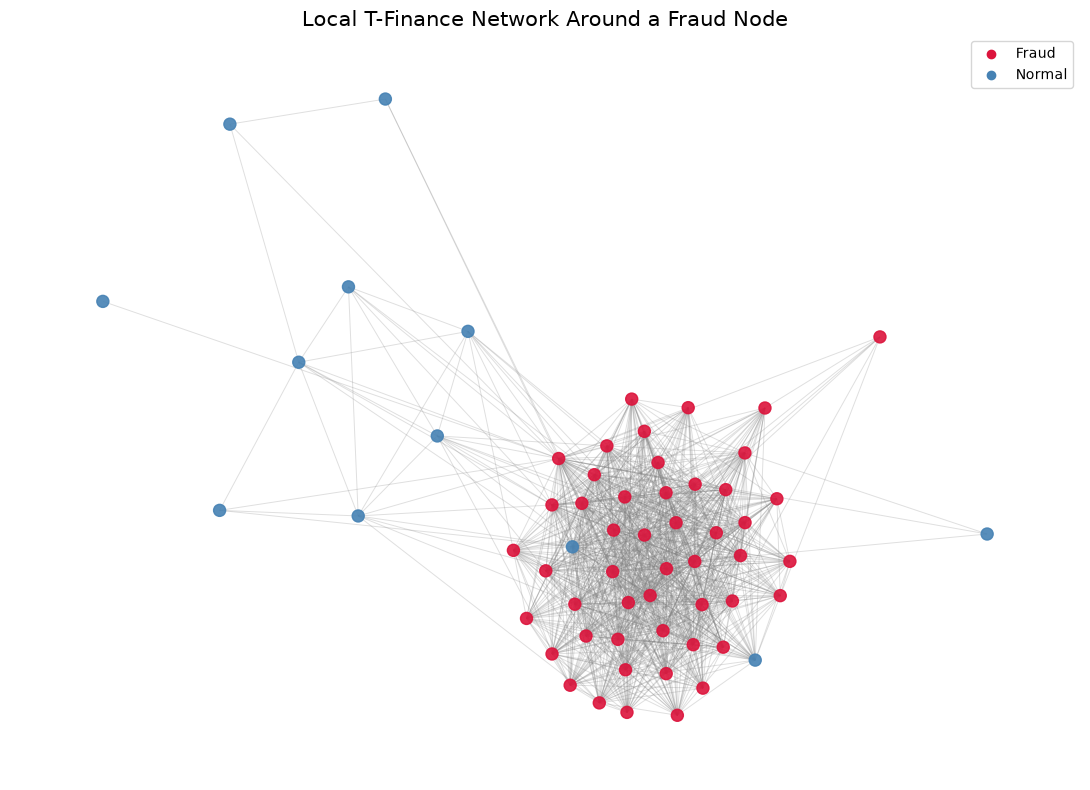

In [73]:
import matplotlib.pyplot as plt
import networkx as nx
import torch
import numpy as np

# Select one fraud node
fraud_nodes = torch.where(labels == 1)[0]
center = fraud_nodes[0].item()

# Get its neighbours
neighbors = torch.cat([
    g_processed.successors(center),
    g_processed.predecessors(center)
]).unique()

# Limit the visualization to a manageable size
neighbors = neighbors[:60]

selected_nodes = torch.cat([
    torch.tensor([center]),
    neighbors
]).unique()

# Extract the induced subgraph
subgraph = dgl.node_subgraph(g_processed, selected_nodes)

# Convert to NetworkX
src, dst = subgraph.edges()
G = nx.Graph()

original_ids = subgraph.ndata[dgl.NID]

for i, original_id in enumerate(original_ids.tolist()):
    G.add_node(
        i,
        label=int(labels[original_id])
    )

G.add_edges_from(zip(src.tolist(), dst.tolist()))

# Node colours
colors = [
    "crimson" if G.nodes[n]["label"] == 1 else "steelblue"
    for n in G.nodes()
]

pos = nx.spring_layout(G, seed=27, k=0.5)

plt.figure(figsize=(11, 8))

nx.draw_networkx_edges(
    G, pos,
    alpha=0.25,
    edge_color="gray",
    width=0.7
)

nx.draw_networkx_nodes(
    G, pos,
    node_color=colors,
    node_size=75,
    alpha=0.9
)

plt.title("Local T-Finance Network Around a Fraud Node", fontsize=15)
plt.scatter([], [], c="crimson", label="Fraud")
plt.scatter([], [], c="steelblue", label="Normal")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.savefig("fraud_centric_network.png", dpi=300)
plt.show()

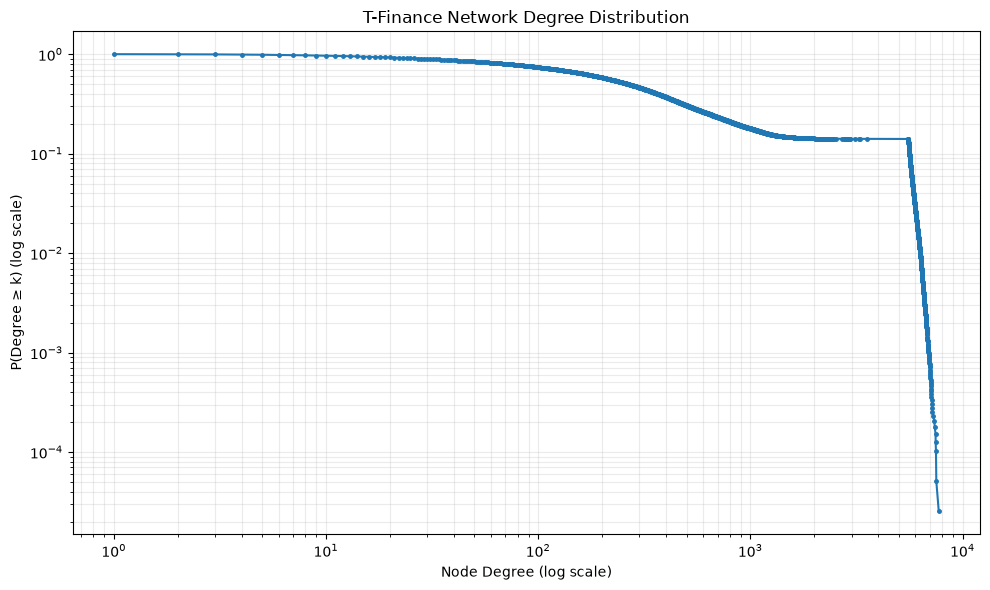

Minimum degree: 1
Maximum degree: 7723
Mean degree: 1078.4634499580761
Median degree: 265.0


In [74]:
import numpy as np
import matplotlib.pyplot as plt

# Calculate the degree of every node
degrees = g_processed.in_degrees().cpu().numpy()

# Sort degrees in descending order
sorted_degrees = np.sort(degrees)[::-1]

# Calculate complementary cumulative degree distribution
unique_degrees = np.unique(sorted_degrees)

ccdf = np.array([
    np.mean(degrees >= d)
    for d in unique_degrees
])

# Plot
plt.figure(figsize=(10, 6))

plt.loglog(
    unique_degrees,
    ccdf,
    marker=".",
    linestyle="-",
    markersize=5
)

plt.xlabel("Node Degree (log scale)")
plt.ylabel("P(Degree ≥ k) (log scale)")
plt.title("T-Finance Network Degree Distribution")
plt.grid(True, which="both", alpha=0.25)

plt.tight_layout()
plt.savefig(
    "tfinance_degree_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Minimum degree:", degrees.min())
print("Maximum degree:", degrees.max())
print("Mean degree:", degrees.mean())
print("Median degree:", np.median(degrees))

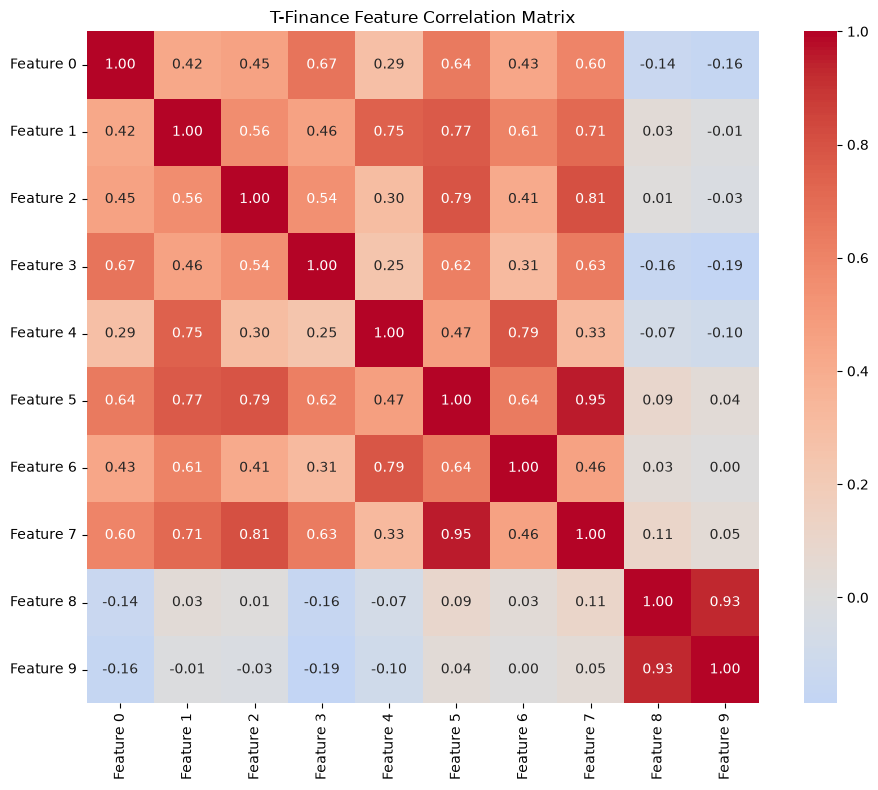

In [76]:
import seaborn as sns
import pandas as pd

feature_df = pd.DataFrame(
    X_standardized.numpy(),
    columns=[f"Feature {i}" for i in range(10)]
)

correlation = feature_df.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    square=True
)

plt.title("T-Finance Feature Correlation Matrix")
plt.tight_layout()

plt.savefig("feature_correlation.png", dpi=300)
plt.show()

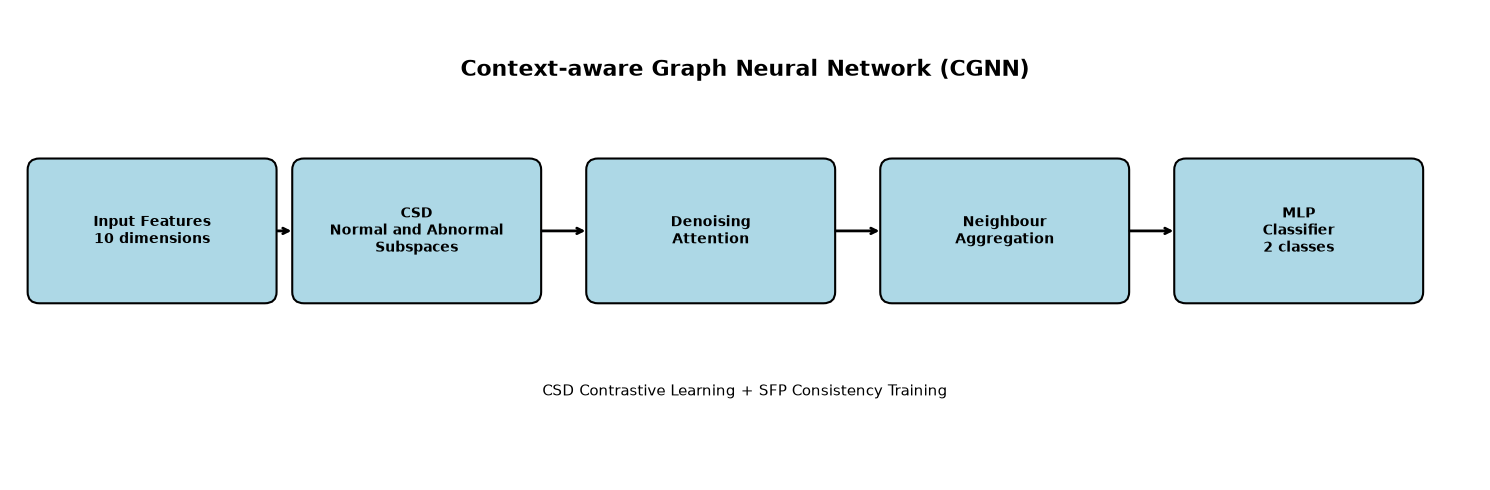

In [77]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 5))

ax.set_xlim(0, 15)
ax.set_ylim(0, 5)
ax.axis("off")

blocks = [
    (0.3, "Input Features\n10 dimensions"),
    (3.0, "CSD\nNormal and Abnormal\nSubspaces"),
    (6.0, "Denoising\nAttention"),
    (9.0, "Neighbour\nAggregation"),
    (12.0, "MLP\nClassifier\n2 classes")
]

for x, label in blocks:
    box = FancyBboxPatch(
        (x, 2), 2.3, 1.3,
        boxstyle="round,pad=0.12",
        edgecolor="black",
        facecolor="lightblue",
        linewidth=1.5
    )
    ax.add_patch(box)

    ax.text(
        x + 1.15, 2.65, label,
        ha="center", va="center",
        fontsize=10, weight="bold"
    )

for i in range(len(blocks) - 1):
    x1 = blocks[i][0] + 2.3
    x2 = blocks[i + 1][0]

    ax.annotate(
        "",
        xy=(x2 - 0.1, 2.65),
        xytext=(x1 + 0.1, 2.65),
        arrowprops=dict(arrowstyle="->", lw=2)
    )

ax.text(
    7.5, 4.3,
    "Context-aware Graph Neural Network (CGNN)",
    ha="center",
    fontsize=16,
    weight="bold"
)

ax.text(
    7.5, 0.9,
    "CSD Contrastive Learning + SFP Consistency Training",
    ha="center",
    fontsize=11
)

plt.tight_layout()
plt.savefig("cgnn_architecture.png", dpi=300)
plt.show()